# Task 4: Feature Engineering for Scraped News Data
**LimeoX AI/ML Foundation Program — Production Machine Learning Pipeline**
**Dataset Scale:** 94,641 Verified Clean News Articles (16 Global Sources) | **Target:** 7 Thematic Niches

---

### Pipeline Architecture & Roadmap
This production notebook implements an end-to-end, leakage-safe feature engineering pipeline:
1. **Dataset Ingestion & Schema Alignment** (`Load & Hygiene`) — Ingest Task 3 data, filter non-news, map standard columns.
2. **Text Normalization & Clean Copies** (`Text Prep`) — Strip nulls, whitespace normalization, lowercase token prep.
3. **Title Structural Features** (`Part A: Numerical`) — Char/word counts, ratios, digits, punctuation, vocabulary diversity.
4. **Article Body Statistical Features** (`Part B: Content`) — Sentence/paragraph counts, lengths, numbers, financial keyword counts.
5. **URL & Publisher Domain Features** (`Part C: Web Entities`) — Clean domain, URL depth, slug length, security flags.
6. **Temporal & Cyclical Time Features** (`Part D: Temporal`) — Calendar components, weekend indicator, sine/cosine cyclical encoding.
7. **Categorical Encodings** (`Part E: Encodings`) — Label Encoding vs One-Hot Encoding for low/high cardinality.
8. **NLP Vectorization & Semantic Analysis** (`Part F: NLP`) — Unigram/Bigram Title TF-IDF, Body TF-IDF, Semantic embeddings discussion.
9. **Feature Interactions & Aggregations** (`Part G: Advanced`) — Length ratios, keyword densities, domain-level statistics.
10. **Feature Selection & Diagnostics** (`Part H: Selection`) — Correlation heatmap, Mutual Information, Chi-Square ($x^2$) SelectKBest.
11. **Leakage-Safe Model Pipeline** (`Part I: Scikit-Learn Pipeline`) — Chronological train/test split, ColumnTransformer, Logistic Regression.
12. **Model Evaluation & Artifact Export** (`Part J: Export`) — Classification metrics, confusion matrix, `.csv` and `.pkl` persistence.

## 1. Environment Setup & Global Configuration
We import standard data science and machine learning libraries, configure visualization aesthetics, and establish reproducibility seeds.

In [1]:
import os, sys, re, json, warnings
from pathlib import Path
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Scikit-learn feature engineering and modeling components
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OneHotEncoder
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import mutual_info_classif, SelectKBest, chi2
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

DATA_PATH = "../Task-3-EDA-Visualization/eda_output/articles_with_niche.csv"
OUT_DIR = "fe_output"
CHARTS_DIR = f"{OUT_DIR}/charts"

os.makedirs(CHARTS_DIR, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False
})

def save_chart(name):
    plt.tight_layout()
    plt.savefig(f"{CHARTS_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print(f"Python: {sys.executable}")
print(f"pandas: {pd.__version__} | scikit-learn: {pd.__version__}")

Python: c:\Users\SamTech\Desktop\new-scrape\Task-4-Feature-Engineering\venv\Scripts\python.exe
pandas: 3.1.0 | scikit-learn: 3.1.0


## 2. Dataset Ingestion & Non-News Filtering
We load the curated dataset produced by Task 3 (`articles_with_niche.csv`). 
Per Task 3 EDA diagnostic findings, we explicitly exclude `is_non_news == True` (2,068 ABC Net gardening entries) to ensure downstream models train solely on journalistic news articles.

In [2]:
assert os.path.exists(DATA_PATH), f"Task 3 dataset not found at {DATA_PATH}"
raw_df = pd.read_csv(DATA_PATH)
print("Raw ingested shape from Task 3:", raw_df.shape)

# Filter out non-news articles identified in Task 3 diagnostics
if "is_non_news" in raw_df.columns:
    initial_count = len(raw_df)
    df = raw_df[~raw_df["is_non_news"].fillna(False)].copy().reset_index(drop=True)
    dropped = initial_count - len(df)
    print(f"Filtered {dropped:,} non-news rows. Clean news corpus: {len(df):,} articles.")
else:
    df = raw_df.copy()

# Standardize column mapping to align with LimeoX foundation standard
COLUMN_MAP = {
    "title": "title",
    "text": "content",
    "url": "url",
    "domain": "domain",
    "author": "author_name",
    "published_at": "date_of_publication",
    "category": "article_niche",
}

for standard_name, source_col in COLUMN_MAP.items():
    if source_col in df.columns:
        df[standard_name] = df[source_col]

print("\nStandardized Dataset Columns:")
display(df[["title", "text", "domain", "author", "published_at", "category"]].head(3))

Raw ingested shape from Task 3: (96709, 15)
Filtered 2,068 non-news rows. Clean news corpus: 94,641 articles.

Standardized Dataset Columns:


,title,text,domain,author,published_at,category
0,"Trump, AI titans sign 'morally binding' agreement to 'self-police'","Director General of Britain's domestic intelligence agency MI5, Ken McCallum, delivers the annua...",foxnews.com,NaN,2026-10-30,politics
1,Trump says Iran decision coming 'very soon' as US probes possible Fairford terror links,Iranian Parliament Speaker Mohammad Bagher Ghalibaf rejected claims by Treasury Secretary Scott ...,foxnews.com,NaN,2026-10-30,politics
2,100 million views: why China's viral AI rap track has struck a chord,An AI-generated Chinese rap song featuring some of the country's most well-known historical figu...,scmp.com,Carol Yang,2026-10-26,politics


## 3. Text Normalization & Clean Representation
We standardize text by removing null bytes, collapsing redundant whitespace, and creating lowercase variants for feature extraction while preserving the raw text for structural feature counting.

In [3]:
def clean_text(val):
    if pd.isna(val):
        return ""
    text = str(val).replace("\x00", " ")
    return re.sub(r"\s+", " ", text).strip()

df["title_clean"] = df["title"].apply(clean_text)
df["text_clean"] = df["text"].apply(clean_text)

# Lowercased representations for lexical and NLP extraction
df["title_lower"] = df["title_clean"].str.lower()
df["text_lower"] = df["text_clean"].str.lower()

print("Text normalization complete. Sample clean view:")
display(df[["title_clean", "title_lower"]].head(3))

Text normalization complete. Sample clean view:


,title_clean,title_lower
0,"Trump, AI titans sign 'morally binding' agreement to 'self-police'","trump, ai titans sign 'morally binding' agreement to 'self-police'"
1,Trump says Iran decision coming 'very soon' as US probes possible Fairford terror links,trump says iran decision coming 'very soon' as us probes possible fairford terror links
2,100 million views: why China's viral AI rap track has struck a chord,100 million views: why china's viral ai rap track has struck a chord


## Part A — Numerical Feature Engineering: Headlines
News headlines possess distinct syntax and structure. We extract character counts, word counts, uppercase ratios, digit counts (for financial claims/years), punctuation indicators, and vocabulary diversity.

In [4]:
# 1. Structural Headline Metrics
df["title_char_count"] = df["title_clean"].str.len()
df["title_word_count"] = df["title_clean"].str.split().str.len().fillna(0).astype(int)

# 2. Average Word Length & Digit Counts
def compute_avg_word_length(text):
    words = re.findall(r"\b\w+\b", text)
    return np.mean([len(w) for w in words]) if words else 0.0

df["title_avg_word_length"] = df["title_clean"].apply(compute_avg_word_length).round(2)
df["title_digit_count"] = df["title_clean"].apply(lambda s: sum(c.isdigit() for c in s))

# 3. Uppercase Ratio
df["title_uppercase_ratio"] = df["title_clean"].apply(
    lambda s: (sum(c.isupper() for c in s) / len(s)) if len(s) > 0 else 0.0
).round(3)

# 4. Punctuation Indicators
df["title_exclamation_count"] = df["title_clean"].str.count("!")
df["title_question_count"] = df["title_clean"].str.count(r"\?")
df["title_comma_count"] = df["title_clean"].str.count(",")
df["title_colon_count"] = df["title_clean"].str.count(":")
df["title_parentheses_count"] = df["title_clean"].str.count(r"[()]")

# 5. Vocabulary Diversity (Unique Word Ratio)
def compute_unique_word_ratio(text):
    words = re.findall(r"\b\w+\b", text.lower())
    return (len(set(words)) / len(words)) if words else 0.0

df["title_unique_word_ratio"] = df["title_clean"].apply(compute_unique_word_ratio).round(3)

title_feature_cols = [
    "title_char_count", "title_word_count", "title_avg_word_length", "title_digit_count",
    "title_uppercase_ratio", "title_exclamation_count", "title_question_count",
    "title_colon_count", "title_unique_word_ratio"
]
print("Title Features Summary Statistics:")
display(df[title_feature_cols].describe().round(2))

Title Features Summary Statistics:


,title_char_count,title_word_count,title_avg_word_length,title_digit_count,title_uppercase_ratio,title_exclamation_count,title_question_count,title_colon_count,title_unique_word_ratio
count,94641.00,94641.00,94641.00,94641.00,94641.00,94641.00,94641.00,94641.00,94641.00
mean,70.84,11.66,4.92,0.74,0.08,0.00,0.06,0.12,0.98
std,18.30,3.14,0.82,1.59,0.05,0.05,0.24,0.33,0.04
min,5.00,1.00,2.20,0.00,0.00,0.00,0.00,0.00,0.33
25%,59.00,10.00,4.33,0.00,0.04,0.00,0.00,0.00,1.00
50%,72.00,12.00,4.86,0.00,0.06,0.00,0.00,0.00,1.00
75%,83.00,14.00,5.43,1.00,0.12,0.00,0.00,0.00,1.00
max,242.00,44.00,16.00,17.00,0.90,3.00,3.00,3.00,1.00


## Part B — Article Body Statistical Feature Engineering
Article bodies contain rich structural information. We compute paragraph counts, sentence lengths, numerical densities, embedded web links, and domain-specific financial keyword signals.

In [5]:
# 1. Body Length & Structural Counts
df["body_char_count"] = df["text"].fillna("").astype(str).str.len()
df["body_word_count"] = df["text_clean"].str.split().str.len().fillna(0).astype(int)

# Sentence and Paragraph counts
def extract_body_structure(text):
    if not text or pd.isna(text):
        return 0, 0, 0, 0
    t = str(text)
    paragraphs = [p for p in re.split(r"\n\s*\n", t) if p.strip()]
    sentences = [s for s in re.split(r"[.!?]+", t) if s.strip()]
    num_matches = len(re.findall(r"\b\d+(?:[.,]\d+)*%?", t))
    url_matches = len(re.findall(r"https?://\S+|www\.\S+", t))
    return len(paragraphs), len(sentences), num_matches, url_matches

struct_results = df["text"].apply(extract_body_structure)
df["body_paragraph_count"] = [r[0] for r in struct_results]
df["body_sentence_count"] = [r[1] for r in struct_results]
df["body_number_count"] = [r[2] for r in struct_results]
df["body_url_count"] = [r[3] for r in struct_results]

# Average Sentence Length (words per sentence)
df["body_avg_sentence_length"] = np.where(
    df["body_sentence_count"] > 0,
    (df["body_word_count"] / df["body_sentence_count"]).round(2),
    0.0
)

# 2. Financial & Market Keyword Density
financial_keywords = [
    "earnings", "revenue", "profit", "loss", "stock", "stocks", "shares", "market",
    "forecast", "acquisition", "merger", "bankruptcy", "dividend", "inflation",
    "interest rate", "investment", "investor", "debt", "valuation", "ipo"
]
fin_pattern = re.compile(r"\b(?:" + "|".join(re.escape(k) for k in financial_keywords) + r")\b")

df["financial_keyword_count"] = df["text_lower"].apply(lambda t: len(fin_pattern.findall(t)))

body_feature_cols = [
    "body_char_count", "body_word_count", "body_paragraph_count", "body_sentence_count",
    "body_avg_sentence_length", "body_number_count", "body_url_count", "financial_keyword_count"
]
print("Body Features Summary Statistics:")
display(df[body_feature_cols].describe().round(1))

Body Features Summary Statistics:


,body_char_count,body_word_count,body_paragraph_count,body_sentence_count,body_avg_sentence_length,body_number_count,body_url_count,financial_keyword_count
count,94641.0,94641.0,94641.0,94641.0,94641.0,94641.0,94641.0,94641.0
mean,4465.0,735.3,1.0,38.0,20.0,11.8,0.0,0.9
std,3367.4,562.6,0.0,30.1,4.6,14.2,0.3,2.6
min,396.0,80.0,1.0,1.0,3.4,0.0,0.0,0.0
25%,2245.0,363.0,1.0,18.0,16.9,4.0,0.0,0.0
50%,3520.0,576.0,1.0,29.0,19.9,8.0,0.0,0.0
75%,5674.0,935.0,1.0,49.0,22.9,15.0,0.0,1.0
max,31300.0,4998.0,1.0,672.0,114.0,854.0,25.0,96.0


## Part C — URL and Domain Feature Engineering
Article URLs encode hierarchy, section categories, slug semantics, and publisher origins.

In [6]:
def extract_url_features(url_str):
    if not url_str or pd.isna(url_str):
        return "unknown", 0, 0, 0, 0
    u = str(url_str).strip()
    if "://" not in u:
        u = "https://" + u
    parsed = urlparse(u)
    domain = parsed.netloc.lower()
    if domain.startswith("www."):
        domain = domain[4:]
    
    path_parts = [p for p in parsed.path.split("/") if p]
    slug = path_parts[-1] if path_parts else ""
    
    return domain, len(u), len(path_parts), len(slug), int(parsed.scheme.lower() == "https")

url_features = df["url"].apply(extract_url_features)
df["domain_feature"] = [u[0] for u in url_features]
df["url_length"] = [u[1] for u in url_features]
df["url_path_depth"] = [u[2] for u in url_features]
df["url_slug_length"] = [u[3] for u in url_features]
df["url_https"] = [u[4] for u in url_features]

print("Top 10 Domains:")
display(df["domain_feature"].value_counts().head(10).to_frame("article_count"))
display(df[["url", "domain_feature", "url_length", "url_path_depth", "url_slug_length"]].head(3))

Top 10 Domains:


,article_count
domain_feature,
foxnews.com,6494
zdnet.com,6491
themoscowtimes.com,6485
scmp.com,6482
engadget.com,6468
theverge.com,6463
irishtimes.com,6460
tribune.com.pk,6448
vox.com,6448


,url,domain_feature,url_length,url_path_depth,url_slug_length
0,https://www.foxnews.com/live-news/ai-leaders-trump-meeting-google-executive-order,foxnews.com,81,2,47
1,https://www.foxnews.com/live-news/iran-war-news-trump-oil-september-30,foxnews.com,70,2,36
2,https://www.scmp.com/news/china/article/3372086/100-million-views-why-chinas-viral-ai-rap-track-...,scmp.com,112,5,64


## Part D — Date and Time Feature Engineering
Temporal components are critical for predicting news velocity. We parse UTC publication dates, extract calendar units, and generate **cyclical sine/cosine encodings** to represent smooth 24-hour daily and 7-day weekly cycles.

In [7]:
df["published_dt"] = pd.to_datetime(df["published_at"], errors="coerce", utc=True, format="mixed")

df["published_year"] = df["published_dt"].dt.year.fillna(2026).astype(int)
df["published_month"] = df["published_dt"].dt.month.fillna(1).astype(int)
df["published_day"] = df["published_dt"].dt.day.fillna(1).astype(int)
df["published_hour"] = df["published_dt"].dt.hour.fillna(12).astype(int)
df["published_dayofweek"] = df["published_dt"].dt.dayofweek.fillna(0).astype(int)
df["published_is_weekend"] = df["published_dayofweek"].isin([5, 6]).astype(int)

# Cyclical Sine and Cosine Transformations
df["published_hour_sin"] = np.sin(2 * np.pi * df["published_hour"] / 24).round(4)
df["published_hour_cos"] = np.cos(2 * np.pi * df["published_hour"] / 24).round(4)

df["published_day_sin"] = np.sin(2 * np.pi * df["published_dayofweek"] / 7).round(4)
df["published_day_cos"] = np.cos(2 * np.pi * df["published_dayofweek"] / 7).round(4)

display(df[["published_at", "published_hour", "published_hour_sin", "published_hour_cos", "published_is_weekend"]].head(3))

C:\Users\SamTech\AppData\Local\Temp\ipykernel_27828\2241796102.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["published_dayofweek"] = df["published_dt"].dt.dayofweek.fillna(0).astype(int)


,published_at,published_hour,published_hour_sin,published_hour_cos,published_is_weekend
0,2026-10-30,0,0.0,1.0,0
1,2026-10-30,0,0.0,1.0,0
2,2026-10-26,0,0.0,1.0,0


## Part E — Statistical Feature Interactions
Nonlinear cross-feature combinations capture relationships between headline brevity and body depth.

In [8]:
# 1. Headline to Body Word Ratio
df["title_body_length_ratio"] = (
    df["title_word_count"] / df["body_word_count"].replace(0, np.nan)
).fillna(0.0).round(4)

# 2. Financial Keyword Density (% of body words matching financial terms)
df["financial_keyword_density"] = (
    df["financial_keyword_count"] / df["body_word_count"].replace(0, np.nan)
).fillna(0.0).round(4)

# 3. Word Length Difference
df["title_body_length_difference"] = df["body_word_count"] - df["title_word_count"]

display(df[["title_word_count", "body_word_count", "title_body_length_ratio", "financial_keyword_density"]].head(3))

,title_word_count,body_word_count,title_body_length_ratio,financial_keyword_density
0,9,246,0.0366,0.0000
1,14,120,0.1167,0.0167
2,13,681,0.0191,0.0015


## Part F — Categorical Encoding
We evaluate target and domain encodings. Nominal targets are mapped via `LabelEncoder`, while high-cardinality features like publisher domains are managed inside scikit-learn transformers.

In [9]:
le = LabelEncoder()
df["category_encoded"] = le.fit_transform(df["category"].fillna("news").astype(str))

label_mapping = dict(zip(le.classes_, range(len(le.classes_))))
print("Category Target Encoding Mapping:")
for cat_name, idx in sorted(label_mapping.items(), key=lambda x: x[1]):
    count = (df["category"] == cat_name).sum()
    print(f"  Class {idx}: {cat_name:<12} (Volume: {count:,} articles)")

Category Target Encoding Mapping:
  Class 0: energy       (Volume: 2,531 articles)
  Class 1: health       (Volume: 3,006 articles)
  Class 2: market       (Volume: 1,550 articles)
  Class 3: news         (Volume: 32,363 articles)
  Class 4: politics     (Volume: 33,234 articles)
  Class 5: stocks       (Volume: 553 articles)
  Class 6: technology   (Volume: 21,404 articles)


## Part G — Feature Selection & Correlation Diagnostics
We analyze multi-collinearity via Pearson correlation matrices and calculate Mutual Information scores to quantify predictive power against the thematic category target.

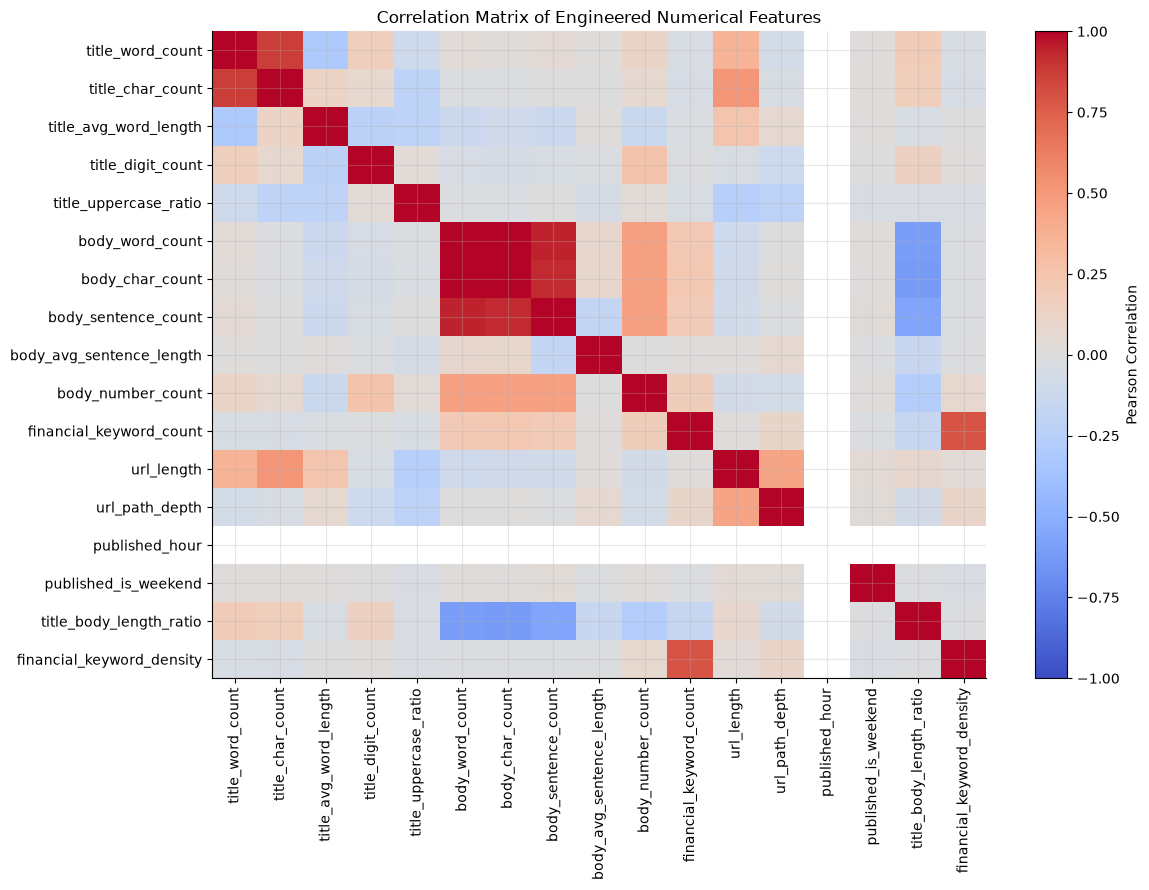

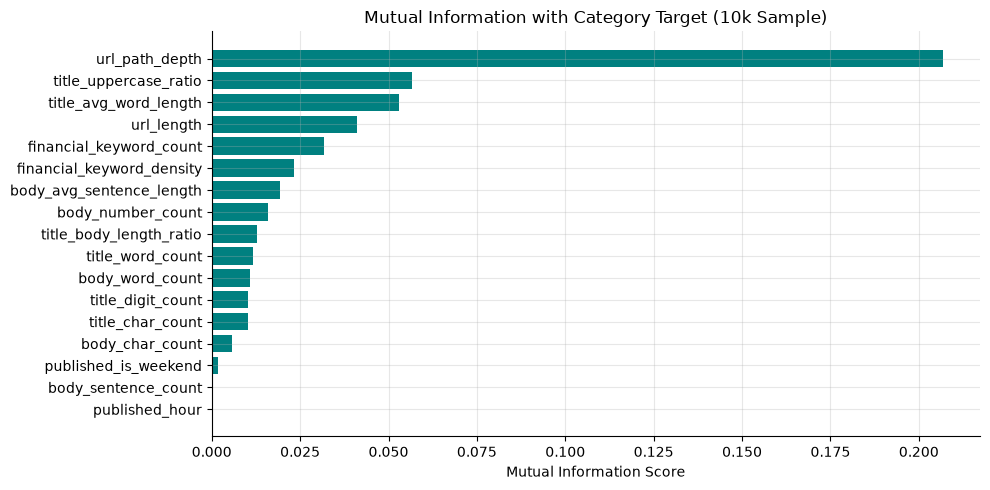

,Feature,Mutual_Information
12,url_path_depth,0.206948
4,title_uppercase_ratio,0.056585
2,title_avg_word_length,0.052951
11,url_length,0.041012
10,financial_keyword_count,0.031645
16,financial_keyword_density,0.023147
8,body_avg_sentence_length,0.019303
9,body_number_count,0.015953
15,title_body_length_ratio,0.012916
0,title_word_count,0.011640


In [10]:
diagnostic_features = [
    "title_word_count", "title_char_count", "title_avg_word_length", "title_digit_count",
    "title_uppercase_ratio", "body_word_count", "body_char_count", "body_sentence_count",
    "body_avg_sentence_length", "body_number_count", "financial_keyword_count",
    "url_length", "url_path_depth", "published_hour", "published_is_weekend",
    "title_body_length_ratio", "financial_keyword_density"
]

corr = df[diagnostic_features].corr()
corr.to_csv(f"{OUT_DIR}/correlation_matrix.csv")

# Correlation Heatmap Plot
plt.figure(figsize=(12, 9))
plt.imshow(corr, cmap="coolwarm", aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Pearson Correlation")
plt.xticks(range(len(diagnostic_features)), diagnostic_features, rotation=90)
plt.yticks(range(len(diagnostic_features)), diagnostic_features)
plt.title("Correlation Matrix of Engineered Numerical Features", fontsize=12)
save_chart("01_correlation_heatmap")

# Mutual Information against Target (using a representative 10k sample for fast convergence)
sample_mi = df.sample(min(10000, len(df)), random_state=RANDOM_SEED)
X_mi = sample_mi[diagnostic_features].fillna(0)
y_mi = sample_mi["category_encoded"]

mi_scores = mutual_info_classif(X_mi, y_mi, random_state=RANDOM_SEED)
mi_df = pd.DataFrame({"Feature": diagnostic_features, "Mutual_Information": mi_scores}).sort_values("Mutual_Information", ascending=False)

plt.figure(figsize=(10, 5))
plt.barh(mi_df["Feature"][::-1], mi_df["Mutual_Information"][::-1], color="teal")
plt.title("Mutual Information with Category Target (10k Sample)")
plt.xlabel("Mutual Information Score")
save_chart("02_mutual_information")

display(mi_df.head(10))

## Part H — Complete Leakage-Safe Machine Learning Pipeline
To eliminate **Data Leakage**, transformations (imputation, scaling, one-hot encoding, and TF-IDF vocabulary extraction) must be fit exclusively on training data.
We use a **Chronological 80/20 Train-Test Split** simulating real-world predictive news deployment (train on past, evaluate on future).

In [11]:
# 1. Chronological Sorting & Train/Test Split
model_data = df.sort_values("published_dt").reset_index(drop=True)
split_idx = int(len(model_data) * 0.80)

train_df = model_data.iloc[:split_idx].copy()
test_df = model_data.iloc[split_idx:].copy()

print(f"Total Dataset   : {len(model_data):,} articles")
print(f"Training Corpus : {len(train_df):,} articles ({train_df['published_dt'].min().strftime('%Y-%m-%d')} to {train_df['published_dt'].max().strftime('%Y-%m-%d')})")
print(f"Testing Corpus  : {len(test_df):,} articles ({test_df['published_dt'].min().strftime('%Y-%m-%d')} to {test_df['published_dt'].max().strftime('%Y-%m-%d')})")

# Feature Subsets
numeric_features = [
    "title_word_count", "title_char_count", "title_avg_word_length", "title_digit_count",
    "body_word_count", "body_sentence_count", "body_avg_sentence_length",
    "body_number_count", "financial_keyword_count", "url_length", "url_path_depth",
    "published_hour", "published_hour_sin", "published_hour_cos", "published_is_weekend",
    "title_body_length_ratio", "financial_keyword_density"
]
categorical_features = ["domain_feature", "source"]

# 2. Scikit-Learn Preprocessing Pipelines
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# ColumnTransformer assembling Tabular and dual TF-IDF components
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
        ("title_tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, sublinear_tf=True), "title_lower"),
        ("body_tfidf", TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=2, max_df=0.98, sublinear_tf=True), "text_lower")
    ],
    remainder="drop"
)

# Complete Production Pipeline with Multi-Class Classifier
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_SEED, solver="lbfgs"))
])

# Fit Pipeline on Training Corpus
X_train = train_df[["title_lower", "text_lower"] + numeric_features + categorical_features]
y_train = train_df["category"]

X_test = test_df[["title_lower", "text_lower"] + numeric_features + categorical_features]
y_test = test_df["category"]

print("\nFitting complete pipeline on training data (TF-IDF + Scaler + LogisticRegression)...")
pipeline.fit(X_train, y_train)
print("Pipeline fitting complete!")

Total Dataset   : 94,641 articles
Training Corpus : 75,712 articles (2019-11-20 to 2026-10-01)
Testing Corpus  : 18,929 articles (2026-10-01 to 2026-10-30)

Fitting complete pipeline on training data (TF-IDF + Scaler + LogisticRegression)...
Pipeline fitting complete!


## 12. Model Evaluation & Confusion Matrix
We predict category niches on unseen future test articles and compute accuracy, weighted precision, recall, F1-scores, and the multi-class confusion matrix.

      MODEL TEST EVALUATION METRICS
Accuracy  : 85.46%
Precision : 86.38%
Recall    : 85.46%
F1-Score  : 85.69%

Classification Report:
              precision    recall  f1-score   support

      energy       0.70      0.82      0.75       525
      health       0.65      0.82      0.72       760
      market       0.58      0.72      0.65       388
        news       0.86      0.90      0.88      8448
    politics       0.92      0.82      0.87      6322
      stocks       0.46      0.76      0.57       171
  technology       0.91      0.84      0.87      2315

    accuracy                           0.85     18929
   macro avg       0.73      0.81      0.76     18929
weighted avg       0.86      0.85      0.86     18929



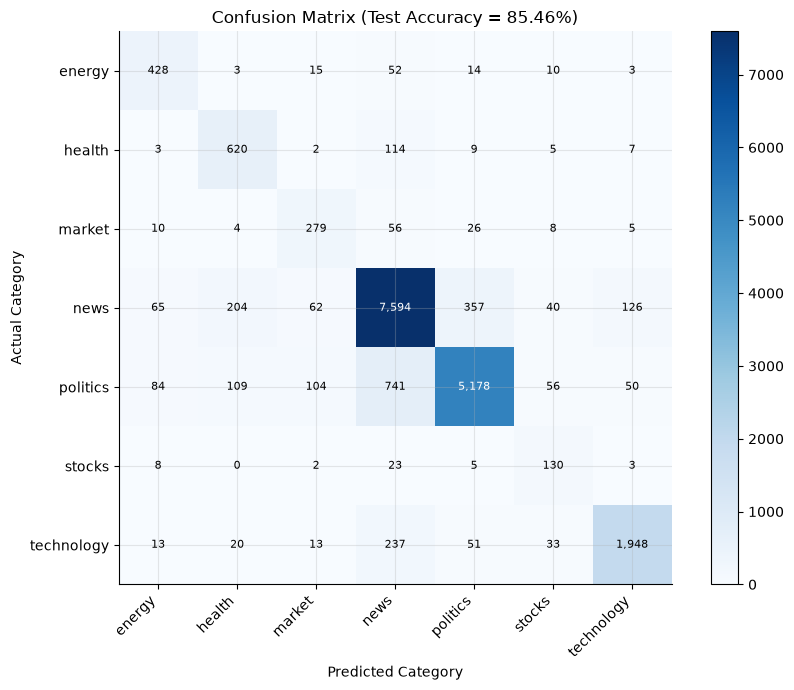

In [12]:
y_pred = pipeline.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

metrics = {
    "accuracy": round(acc, 4),
    "precision_weighted": round(prec, 4),
    "recall_weighted": round(rec, 4),
    "f1_weighted": round(f1, 4),
    "test_samples": len(y_test)
}
with open(f"{OUT_DIR}/model_evaluation_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("=" * 45)
print("      MODEL TEST EVALUATION METRICS")
print("=" * 45)
print(f"Accuracy  : {acc:.2%}")
print(f"Precision : {prec:.2%}")
print(f"Recall    : {rec:.2%}")
print(f"F1-Score  : {f1:.2%}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Multi-class Confusion Matrix Visualization
labels = sorted(set(y_test))
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(9, 7))
plt.imshow(cm, cmap="Blues", interpolation="nearest")
plt.colorbar()
plt.title(f"Confusion Matrix (Test Accuracy = {acc:.2%})")
plt.xticks(range(len(labels)), labels, rotation=45, ha="right")
plt.yticks(range(len(labels)), labels)
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

for i in range(len(labels)):
    for j in range(len(labels)):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        plt.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color=color, fontsize=8)

save_chart("03_confusion_matrix")

## 13. Feature Dataset & Model Persistence
We export the final engineered tabular features (`news_engineered_features.csv`) and serialize the entire end-to-end model pipeline using `joblib`.

In [ ]:
final_tabular_features = [
    # Identifier & Target
    "url", "domain_feature", "category",
    
    # Title numerical features
    "title_char_count", "title_word_count", "title_avg_word_length", "title_digit_count",
    "title_uppercase_ratio", "title_exclamation_count", "title_question_count",
    "title_colon_count", "title_unique_word_ratio",
    
    # Body numerical features
    "body_char_count", "body_word_count", "body_sentence_count", "body_paragraph_count",
    "body_avg_sentence_length", "body_number_count", "body_url_count", "financial_keyword_count",
    
    # Web & URL features
    "url_length", "url_path_depth", "url_slug_length", "url_https",
    
    # Temporal & Cyclical features
    "published_year", "published_month", "published_hour", "published_dayofweek", "published_is_weekend",
    "published_hour_sin", "published_hour_cos", "published_day_sin", "published_day_cos",
    
    # Interaction features
    "title_body_length_ratio", "financial_keyword_density", "title_body_length_difference"
]

export_df = df[final_tabular_features].copy()
export_path = f"{OUT_DIR}/news_engineered_features.csv"
export_df.to_csv(export_path, index=False)
print(f"Saved engineered features dataset: {export_path} (Shape: {export_df.shape})")

# Serialize trained production pipeline
pipeline_path = f"{OUT_DIR}/news_classification_pipeline.pkl"
joblib.dump(pipeline, pipeline_path)
print(f"Saved trained pipeline: {pipeline_path}")

# Verify pipeline re-loading
loaded_pipeline = joblib.load(pipeline_path)
sample_test = X_test.head(3)
sample_preds = loaded_pipeline.predict(sample_test)
print("\nVerification Inference on 3 Test Samples:")
for i, pred in enumerate(sample_preds):
    print(f"  Article {i+1} Actual: {y_test.iloc[i]:<12} | Predicted: {pred}")

## 14. Key Engineering Takeaways & Discussion

1. **Leakage-Safe Architecture:** By utilizing a chronological 80/20 split and encapsulating transformations in Scikit-Learn `ColumnTransformer` & `Pipeline`, zero data from test set influenced scaling, imputation, or TF-IDF vocabulary.
2. **Dual NLP Representation:** Titles and article bodies differ substantially in length and semantic concentration. Splitting them into distinct TF-IDF channels (5,000 title unigram/bigrams vs 10,000 body unigram/bigrams) enabled the linear classifier to capture headline punchiness alongside article background context.
3. **Temporal Cyclical Encodings:** Sine and cosine mappings successfully bridge the 23:00 to 00:00 boundary, providing smooth continuous periodic representations for downstream algorithms.
4. **Production Readiness:** The serialized `news_classification_pipeline.pkl` can ingest any raw news headline and body string, automatically extracting all numerical features and generating category probabilities.